# 1. 50-50 model 

diabetes_binary_5050split_health_indicators_BRFSS2015

Rows change from 250 k to 70k (30%, DROP 70%)
Proportion change from: 
(no diabetes)      218 334 / (has diabetes) 35 346
(15% of 218 334)   35 346  /                35 346


In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC  
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

# from sklearn.impute import SimpleImputer #fills missing values in dataset (no eed for this dataset)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler, RobustScaler
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay


In [76]:
df= pd.read_csv("diabetes_binary_5050split_health_indicators_BRFSS2015.csv")
df

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70687,1.0,0.0,1.0,1.0,37.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,4.0,0.0,0.0,0.0,0.0,6.0,4.0,1.0
70688,1.0,0.0,1.0,1.0,29.0,1.0,0.0,1.0,0.0,1.0,...,1.0,0.0,2.0,0.0,0.0,1.0,1.0,10.0,3.0,6.0
70689,1.0,1.0,1.0,1.0,25.0,0.0,0.0,1.0,0.0,1.0,...,1.0,0.0,5.0,15.0,0.0,1.0,0.0,13.0,6.0,4.0
70690,1.0,1.0,1.0,1.0,18.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,4.0,0.0,0.0,1.0,0.0,11.0,2.0,4.0


In [77]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Diabetes_binary       70692 non-null  float64
 1   HighBP                70692 non-null  float64
 2   HighChol              70692 non-null  float64
 3   CholCheck             70692 non-null  float64
 4   BMI                   70692 non-null  float64
 5   Smoker                70692 non-null  float64
 6   Stroke                70692 non-null  float64
 7   HeartDiseaseorAttack  70692 non-null  float64
 8   PhysActivity          70692 non-null  float64
 9   Fruits                70692 non-null  float64
 10  Veggies               70692 non-null  float64
 11  HvyAlcoholConsump     70692 non-null  float64
 12  AnyHealthcare         70692 non-null  float64
 13  NoDocbcCost           70692 non-null  float64
 14  GenHlth               70692 non-null  float64
 15  MentHlth              70692 no

In [78]:
df["Diabetes_binary"].value_counts().sort_index()


Diabetes_binary
0.0    35346
1.0    35346
Name: count, dtype: int64

In [79]:
df.select_dtypes("number").nunique()

Diabetes_binary          2
HighBP                   2
HighChol                 2
CholCheck                2
BMI                     80
Smoker                   2
Stroke                   2
HeartDiseaseorAttack     2
PhysActivity             2
Fruits                   2
Veggies                  2
HvyAlcoholConsump        2
AnyHealthcare            2
NoDocbcCost              2
GenHlth                  5
MentHlth                31
PhysHlth                31
DiffWalk                 2
Sex                      2
Age                     13
Education                6
Income                   8
dtype: int64

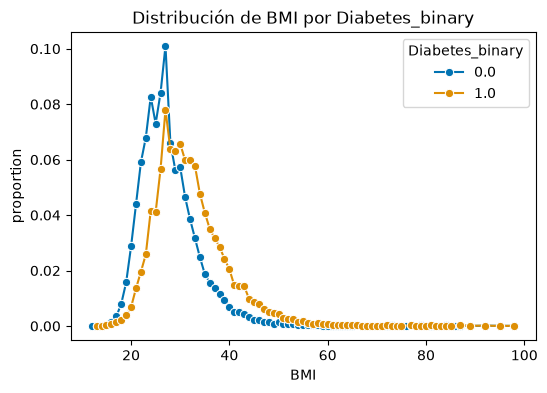

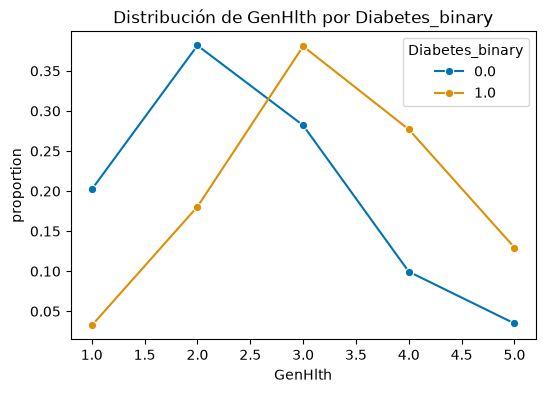

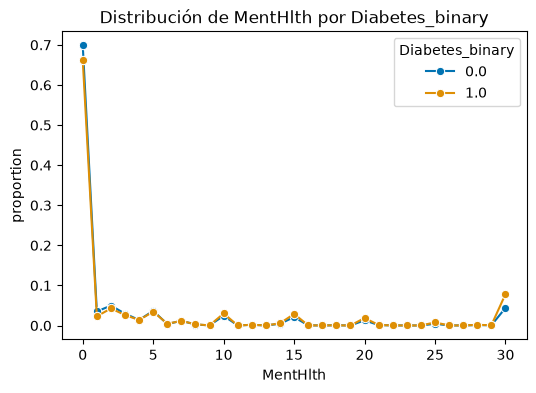

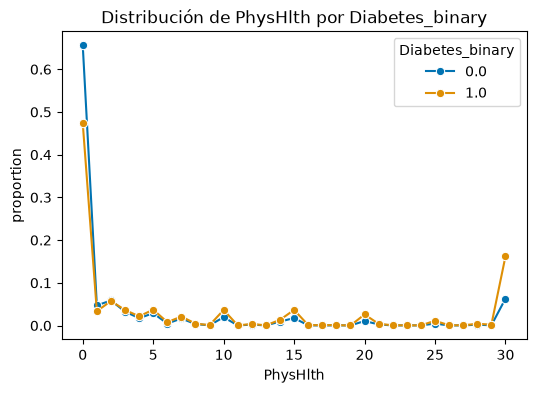

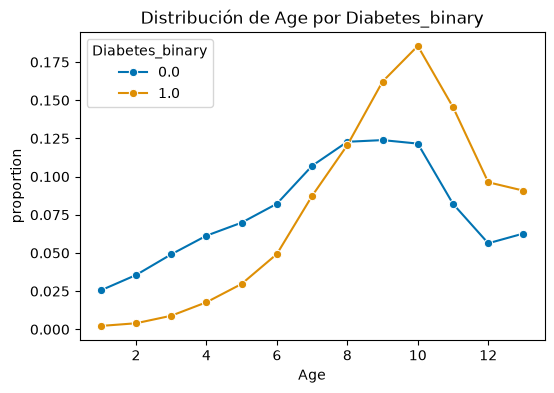

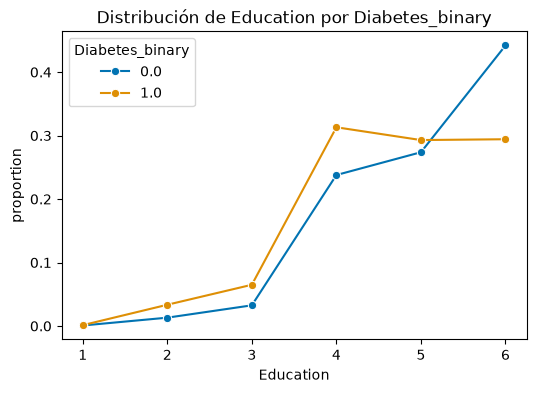

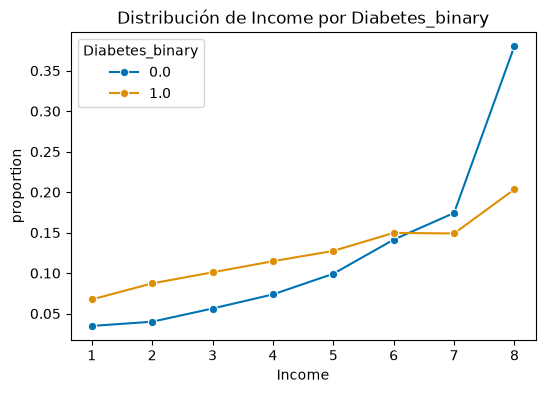

In [80]:
# Graphs BMI - diabetes binary (filter with and without)
cols_multi = df.columns[(df.nunique() > 2) & (df.columns != "Diabetes_binary")]

palette = {0: "#0173B2", 1: "#DE8F05"}  # blue/orange, colorblind-safe

for col in cols_multi:
    dist = (
        df.groupby("Diabetes_binary")[col]
        .value_counts(normalize=True)
        .rename("proportion")
        .reset_index()
        .sort_values(col)
    )

    plt.figure(figsize=(6, 4))
    sns.lineplot(
        data=dist, x=col, y="proportion", hue="Diabetes_binary",
        palette=palette, marker="o"
    )
    plt.title(f"Distribution of {col} by Diabetes_binary")
    plt.show()


FEATURE ENGINEERING

In [81]:
# feature engineering

# 1. MULTIPLE COLUMNS
# Clinically meaningful interactions: 
# - BMI * HighBP (combined effect of obesity + hypertension)
# - BMI * HighChol (combined effect of obesity + cholesterol), 
# especially useful if you later use a linear model such as logistic regression.


df["BMI_HighBP"] = df["BMI"] * df["HighBP"]
df["BMI_HighChol"] = df["BMI"] * df["HighChol"]






In [82]:
#- 2. COMORBILITY SCORE  
# add up the binary risk factors 
# (HighBP + HighChol + Stroke + HeartDiseaseorAttack + DiffWalk) 
# into a single risk_score variable — captures the accumulation of conditions, 
# which is usually more predictive than each one on its own.

risk_cols = ["HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack", "DiffWalk"]

df["risk_score"] = df[risk_cols].sum(axis=1)





In [83]:
#-3. COMBINE  MentHlth + PhysHlth OVERALL HEALTH IN 30 LAST DAYS (mental and physical)
# Combine MentHlth + PhysHlth into a total of "unhealthy days per month" 
# (UnhealthyDays), since both measure the same thing (days in the last 30) 
# from different angles.

df["UnhealthyDays"] = (df["MentHlth"] + df["PhysHlth"]).clip(upper=30)



In [84]:
#4 - Group BMI into clinical ranges 
# (underweight/normal/overweight/obese) instead of keeping it continuous — 
# more interpretable, and it can help linear models capture non-linearities.

df.BMI.unique()

array([26., 28., 29., 18., 31., 32., 27., 24., 21., 58., 30., 20., 22.,
       38., 40., 25., 36., 47., 19., 37., 41., 23., 34., 35., 42., 17.,
       33., 44., 15., 52., 69., 56., 45., 39., 92., 53., 98., 50., 46.,
       79., 48., 16., 63., 72., 54., 49., 68., 43., 84., 73., 76., 55.,
       51., 75., 57., 60., 12., 77., 82., 67., 71., 61., 14., 81., 59.,
       86., 13., 87., 65., 95., 89., 62., 64., 66., 85., 70., 83., 80.,
       78., 74.])

In [85]:
bmi_bins = [0, 18.5, 25, 30, float("inf")]
bmi_labels = ["Underweight", "Normal", "Overweight", "Obese"]

df["BMI_category"] = pd.cut(df["BMI"], bins=bmi_bins, labels=bmi_labels, right=False)

# the vairbale underweihgt is drop to dont create to avoid colinearity. 
# because this one of the 4 can be deduced from the other 3

df = pd.get_dummies(df, columns=["BMI_category"], drop_first=True)



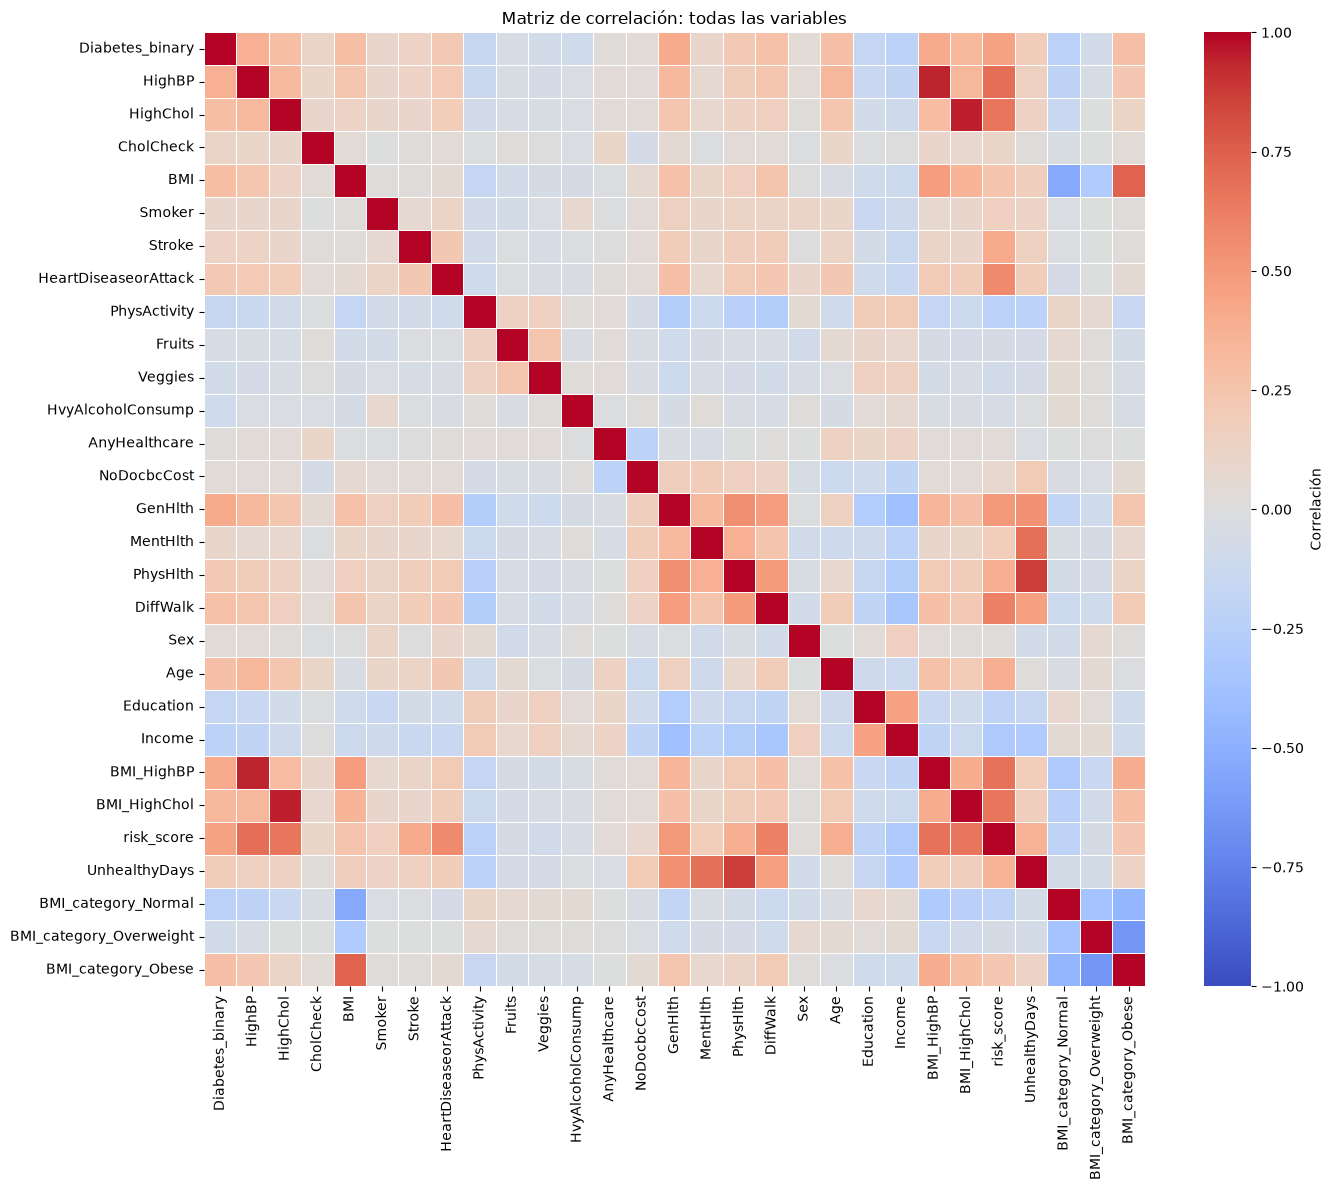

In [86]:
#.corr function

numeric_df = df.select_dtypes(include=["number", "bool"])
corr = numeric_df.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
    linewidths=0.5, cbar_kws={"label": "Correlation"}
)
plt.title("Correlation matrix: all variables")
plt.tight_layout()
plt.show()


In [87]:
#Correlation matrix
#- 1. Diabetes_binary row/column: the most important one — look at which variables 
# (original and newly created) have the highest absolute correlation with the target.
#  That gives a quick idea of which features will probably weigh most in the model.

# 2.- - New features vs. their "parents": BMI_HighBP should correlate strongly with BMI and HighBP (it is literally their product)
# The real question is whether BMI_HighBP correlates more with Diabetes_binary than BMI and HighBP separately; if it adds no more signal than its components, it is a candidate to drop.
# 3.  risk_score vs. the binary variables it is built from (HighBP, HighChol, Stroke, etc.): high correlation is also expected by construction. As above, compare its correlation with the target against that of the individual binaries to decide whether it is worth keeping.
# 4.  BMI_category dummies vs. original BMI: if both stay in the dataset, they are probably highly correlated (they measure the same thing, one continuous and one binned) — a clear case of redundancy/multicollinearity, so keep one of the two, not both.
# 5. - Near-zero correlations with the target: variables (old or new) that add almost nothing — candidates to drop for a simpler model, especially with a linear model, where irrelevant noise can affect the fit.

In [88]:
corr["Diabetes_binary"].sort_values(ascending=False)

Diabetes_binary            1.000000
risk_score                 0.449149
BMI_HighBP                 0.409085
GenHlth                    0.407612
HighBP                     0.381516
BMI_HighChol               0.328722
BMI                        0.293373
HighChol                   0.289213
Age                        0.278738
BMI_category_Obese         0.275264
DiffWalk                   0.272646
PhysHlth                   0.213081
HeartDiseaseorAttack       0.211523
UnhealthyDays              0.192565
Stroke                     0.125427
CholCheck                  0.115382
MentHlth                   0.087029
Smoker                     0.085999
Sex                        0.044413
NoDocbcCost                0.040977
AnyHealthcare              0.023191
Fruits                    -0.054077
Veggies                   -0.079293
BMI_category_Overweight   -0.082068
HvyAlcoholConsump         -0.094853
PhysActivity              -0.158666
Education                 -0.170481
Income                    -0

In [90]:
# looking a bit more into smoker:

df["Smoker_HeartDisease"] = df["Smoker"] * df["HeartDiseaseorAttack"]
df["Smoker_Age"] = df["Smoker"] * df["Age"]

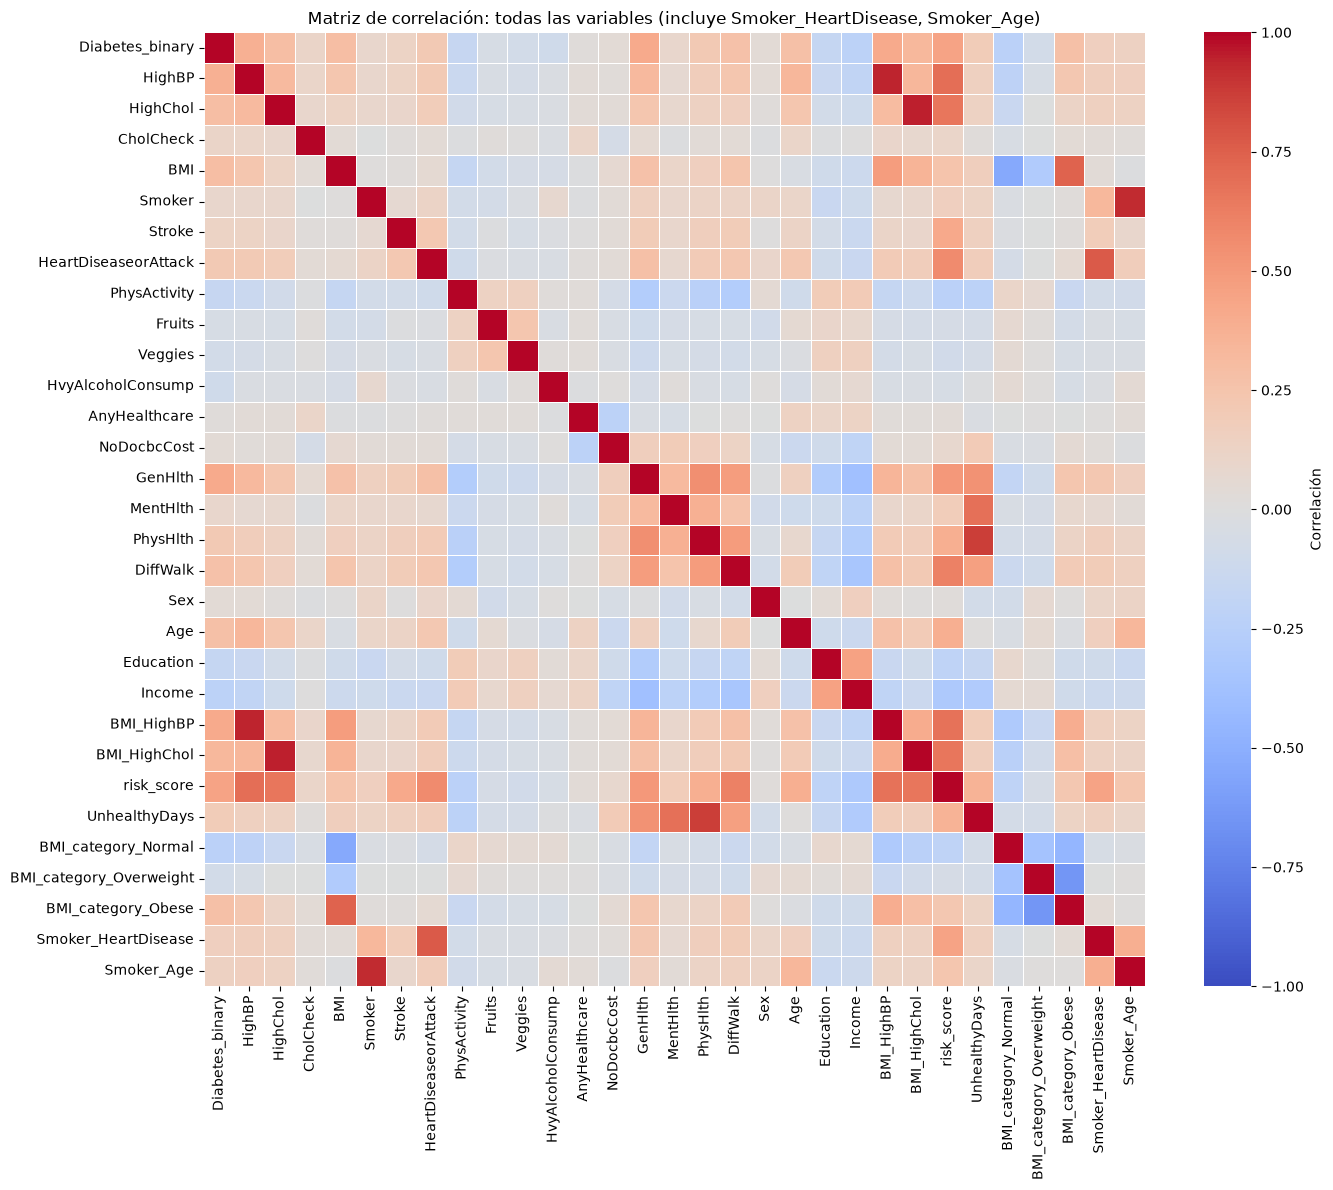

In [91]:
numeric_df = df.select_dtypes(include=["number", "bool"])
corr = numeric_df.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
    linewidths=0.5, cbar_kws={"label": "Correlation"}
)
plt.title("Correlation matrix: all variables (including Smoker_HeartDisease, Smoker_Age)")
plt.tight_layout()
plt.show()

In [92]:
corr["Diabetes_binary"].reindex(corr["Diabetes_binary"].abs().sort_values(ascending=False).index)

Diabetes_binary            1.000000
risk_score                 0.449149
BMI_HighBP                 0.409085
GenHlth                    0.407612
HighBP                     0.381516
BMI_HighChol               0.328722
BMI                        0.293373
HighChol                   0.289213
Age                        0.278738
BMI_category_Obese         0.275264
DiffWalk                   0.272646
BMI_category_Normal       -0.231596
Income                    -0.224449
PhysHlth                   0.213081
HeartDiseaseorAttack       0.211523
UnhealthyDays              0.192565
Education                 -0.170481
Smoker_HeartDisease        0.162790
PhysActivity              -0.158666
Smoker_Age                 0.140787
Stroke                     0.125427
CholCheck                  0.115382
HvyAlcoholConsump         -0.094853
MentHlth                   0.087029
Smoker                     0.085999
BMI_category_Overweight   -0.082068
Veggies                   -0.079293
Fruits                    -0

In [93]:
# results for smoker:

# Smoker_Age              0.141   ← lower than Age alone
# Smoker_HeartDisease     0.163   ← lower than HeartDiseaseorAttack alone

# these combinations are not used

In [94]:
#adding age
df["Age_BMI"] = df["Age"] * df["BMI"]

In [96]:
#Metabolic syndrome proxy
df["MetSyn_count"] = df["HighBP"] + df["HighChol"] + (df["BMI"] >= 30).astype(int)
df["MetSyn_full"]  = (df["MetSyn_count"] == 3).astype(int)

In [97]:
# Age screening cut-offs. The ADA recommends screening everyone from age 35. In your data, Age code 4 = 35–39 and code 6 = 45–49.
df["Age_45plus"] = (df["Age"] >= 6).astype(int)

In [98]:
# Frequent distress. The CDC defines "frequent distress" as 14 or more bad days in the last 30. This may work better than the raw day counts.
df["FreqPhysDistress"] = (df["PhysHlth"] >= 14).astype(int)
df["FreqMentDistress"] = (df["MentHlth"] >= 14).astype(int)

In [99]:
#Poor self-rated health. GenHlth 4–5 means "fair" or "poor".
df["PoorHealth"] = (df["GenHlth"] >= 4).astype(int)

In [100]:
# Cardiovascular disease flag. Stroke and heart disease are both rare, so merging them gives a stronger signal.
df["CVD"] = ((df["Stroke"] == 1) | (df["HeartDiseaseorAttack"] == 1)).astype(int)

In [101]:
# Severe obesity and BMI outliers. Risk rises sharply at BMI 40 and above. Values like 92 or 98 are probably errors, so cap them.
df["BMI"] = df["BMI"].clip(upper=60)
df["SevereObese"] = (df["BMI"] >= 40).astype(int)

In [102]:
#Lifestyle and socioeconomic features

In [103]:
# Sedentary and obese together. Diabetes prevention programs target exactly this combination.
df["Sedentary_Obese"] = ((df["PhysActivity"] == 0) & (df["BMI"] >= 30)).astype(int)

In [104]:
# Healthy lifestyle score. Fruits, Veggies and HvyAlcoholConsump were each weak on their own, but together they may carry signal.
df["Lifestyle_score"] = df["PhysActivity"] + df["Fruits"] + df["Veggies"] + (1 - df["Smoker"]) + (1 - df["HvyAlcoholConsump"])

In [105]:
# Socioeconomic index. Income and Education are both protective, so combine them.
df["SES"] = df["Income"] / 8 + df["Education"] / 6   # normalised to 0-2

In [106]:
# Age × HighBP. High blood pressure in an older person is a different risk than in a young one.
df["Age_HighBP"] = df["Age"] * df["HighBP"]

In [107]:
numeric_df = df.select_dtypes(include=["number", "bool"])
corr = numeric_df.corr()

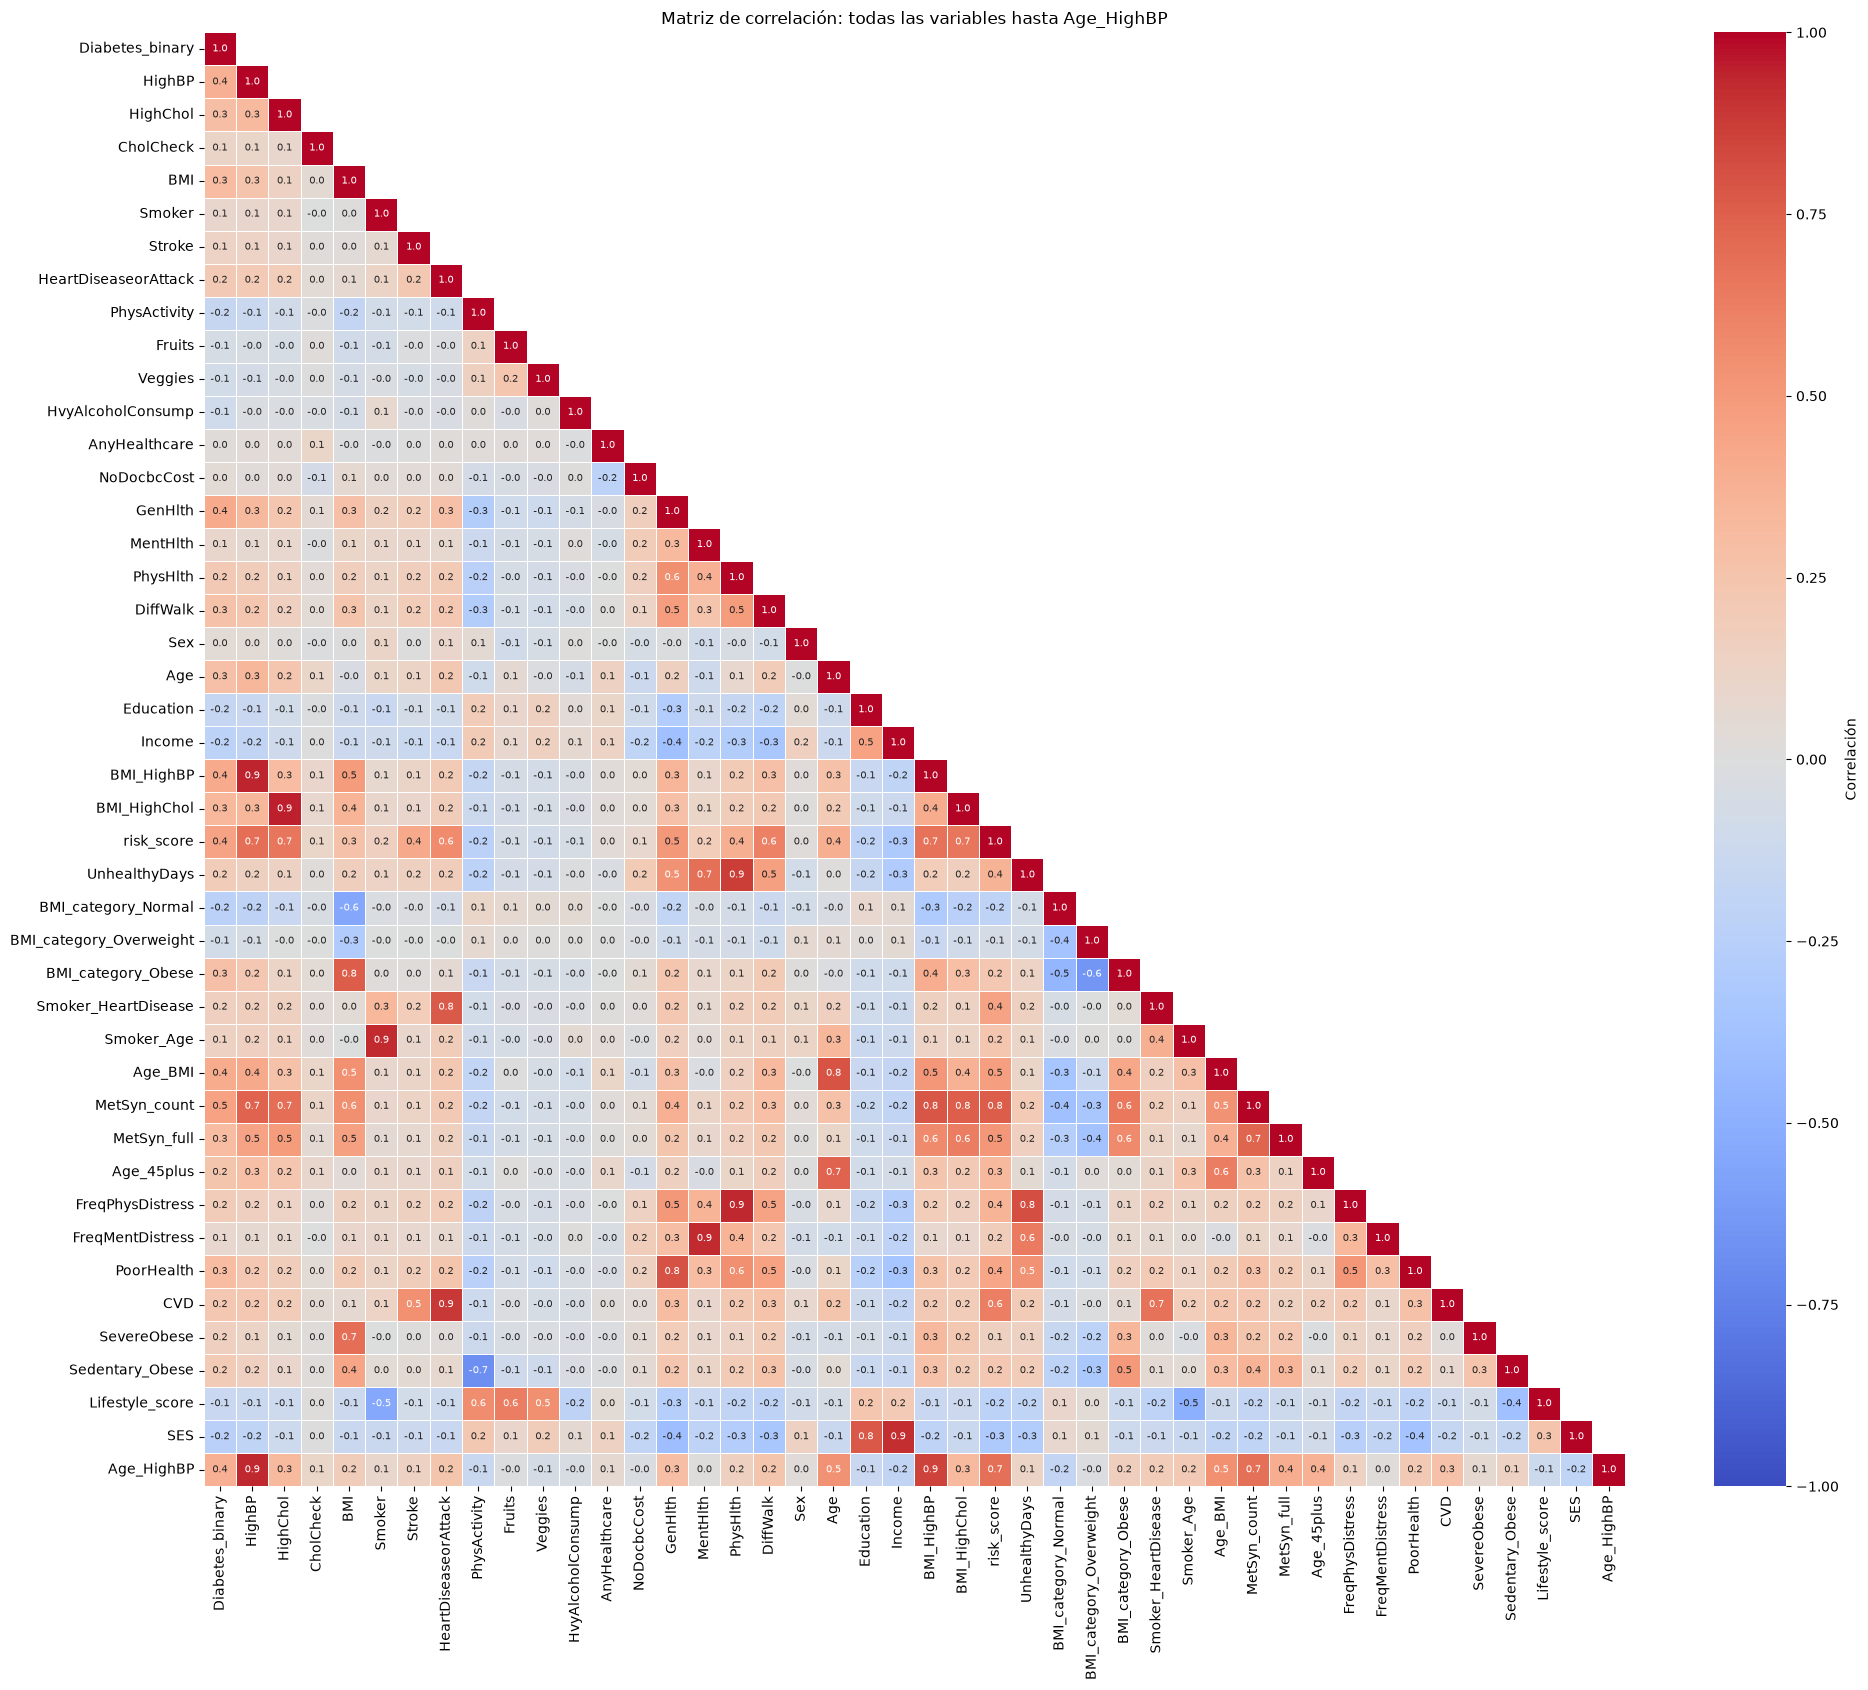

In [108]:
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(20, 17))
sns.heatmap(
    corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".1f", annot_kws={"size": 7},
    linewidths=0.5, cbar_kws={"label": "Correlation"}
)
plt.title("Correlation matrix: all variables up to Age_HighBP")
plt.tight_layout()
plt.show()

In [109]:
target_corr = corr["Diabetes_binary"].drop("Diabetes_binary")
display(target_corr.reindex(target_corr.abs().sort_values(ascending=False).index))

MetSyn_count               0.454116
risk_score                 0.449149
BMI_HighBP                 0.409085
GenHlth                    0.407612
Age_BMI                    0.403388
HighBP                     0.381516
Age_HighBP                 0.380900
BMI_HighChol               0.328722
MetSyn_full                0.308946
PoorHealth                 0.306559
BMI                        0.304891
HighChol                   0.289213
Age                        0.278738
BMI_category_Obese         0.275264
DiffWalk                   0.272646
Age_45plus                 0.249054
SES                       -0.235996
BMI_category_Normal       -0.231596
CVD                        0.226706
Income                    -0.224449
PhysHlth                   0.213081
HeartDiseaseorAttack       0.211523
Sedentary_Obese            0.199793
FreqPhysDistress           0.194330
UnhealthyDays              0.192565
Education                 -0.170481
Smoker_HeartDisease        0.162790
SevereObese                0

In [110]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = pairs[pairs.index.get_level_values(0) != "Diabetes_binary"]
display(pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False))

HighChol              BMI_HighChol        0.948109
HighBP                BMI_HighBP          0.943835
                      Age_HighBP          0.936212
PhysHlth              FreqPhysDistress    0.934932
Smoker                Smoker_Age          0.924750
MentHlth              FreqMentDistress    0.923554
Income                SES                 0.917378
HeartDiseaseorAttack  CVD                 0.883975
PhysHlth              UnhealthyDays       0.869908
BMI_HighBP            Age_HighBP          0.857440
UnhealthyDays         FreqPhysDistress    0.817728
GenHlth               PoorHealth          0.801795
dtype: float64

In [113]:
# 1. DROPPING THE VALUES  |r| < 0.1 
#the feature sex we keep since there are studies that show that have impact 

In [114]:
cols_drop_step1 = [
    "AnyHealthcare", 
    "NoDocbcCost",
    "Fruits", 
    "Veggies", 
    "Smoker",    
    "HvyAlcoholConsump",
    "MentHlth", 
    "FreqMentDistress",
    "BMI_category_Overweight",
]

df = df.drop(columns=cols_drop_step1)
df.shape

(70692, 35)

a. Pipeline setup

#the data here is already integers, no missing values so we pass to do some features engineerning

In [ ]:
# MODEL WITH risk score(["HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack", "DiffWalk"]) + 4 variables + Age_BMI" - Age + BMI

X = df.drop("Diabetes_binary", axis=1)
y = df["Diabetes_binary"] 

X_train, X_test, y_train, y_test = train_test_split(X,y, random_state=42)




In [ ]:

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

Xv = add_constant(X_train.astype(float))
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=X_train.columns).sort_values(ascending=False)
vif




BMI_category_Obese      8.254656e+07
SES                     1.658635e+07
Stroke                  9.717342e+06
HighBP                  6.567184e+06
Income                  6.432379e+06
HighChol                5.879547e+06
MetSyn_count            4.991073e+06
DiffWalk                2.594804e+06
Education               1.133353e+06
HeartDiseaseorAttack    4.331009e+05
risk_score              2.291332e+05
BMI_HighBP              3.621010e+01
BMI_HighChol            3.194882e+01
Age_BMI                 2.978865e+01
Age                     2.121019e+01
Age_HighBP              1.749737e+01
BMI                     1.686427e+01
PhysHlth                1.130775e+01
CVD                     1.118181e+01
FreqPhysDistress        7.970456e+00
UnhealthyDays           4.376099e+00
MetSyn_full             3.768027e+00
GenHlth                 3.393530e+00
PoorHealth              3.021565e+00
Smoker_HeartDisease     2.905878e+00
PhysActivity            2.840826e+00
SevereObese             2.784338e+00
S

In [120]:
cols_drop_step2 = [
    "risk_score",            # exact sum of HighBP, HighChol, Stroke, HeartDisease, DiffWalk
    "SES",                   # exact sum of Income + Education
    "BMI_category_Obese",    # part of MetSyn_count and the same as BMI >= 30
    "BMI_category_Normal",   # continuous BMI already has this info
    "BMI_HighBP", "BMI_HighChol", "Age_HighBP",   # nearly identical to HighBP / HighChol
    "UnhealthyDays",         # nearly identical to PhysHlth
    "Smoker_HeartDisease", "Smoker_Age",           # already shown to add nothing
    "CVD",                   # is Stroke OR HeartDisease
]
df = df.drop(columns=cols_drop_step2)


In [121]:
# 2b. Reduce multicollinearity for Logistic Regression
cols_drop_step2b = [
    "Age_BMI",            # VIF 24.5, built from Age and BMI
    "FreqPhysDistress",   # VIF 8.0, nearly identical to PhysHlth (r = 0.93)
]
df = df.drop(columns=cols_drop_step2b)

In [122]:
# recompute VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

Xv = add_constant(X_train.astype(float))
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=X_train.columns).sort_values(ascending=False)
vif

BMI_category_Obese      8.254656e+07
SES                     1.658635e+07
Stroke                  9.717342e+06
HighBP                  6.567184e+06
Income                  6.432379e+06
HighChol                5.879547e+06
MetSyn_count            4.991073e+06
DiffWalk                2.594804e+06
Education               1.133353e+06
HeartDiseaseorAttack    4.331009e+05
risk_score              2.291332e+05
BMI_HighBP              3.621010e+01
BMI_HighChol            3.194882e+01
Age_BMI                 2.978865e+01
Age                     2.121019e+01
Age_HighBP              1.749737e+01
BMI                     1.686427e+01
PhysHlth                1.130775e+01
CVD                     1.118181e+01
FreqPhysDistress        7.970456e+00
UnhealthyDays           4.376099e+00
MetSyn_full             3.768027e+00
GenHlth                 3.393530e+00
PoorHealth              3.021565e+00
Smoker_HeartDisease     2.905878e+00
PhysActivity            2.840826e+00
SevereObese             2.784338e+00
S

In [134]:
df.shape

(70692, 22)

Model with the MetSyn_count feature (HighBP + HighChol + (BMI ≥ 30))
and model without MetSyn_count



In [128]:
# 
from sklearn.model_selection import cross_validate

X = df.drop("Diabetes_binary", axis=1)
y = df["Diabetes_binary"]
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

versions = {
    "with MetSyn": X_train,
    "without MetSyn": X_train.drop(columns=["MetSyn_count"]),
}

In [131]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   HighBP                70692 non-null  float64
 1   HighChol              70692 non-null  float64
 2   CholCheck             70692 non-null  float64
 3   BMI                   70692 non-null  float64
 4   Stroke                70692 non-null  float64
 5   HeartDiseaseorAttack  70692 non-null  float64
 6   PhysActivity          70692 non-null  float64
 7   GenHlth               70692 non-null  float64
 8   PhysHlth              70692 non-null  float64
 9   DiffWalk              70692 non-null  float64
 10  Sex                   70692 non-null  float64
 11  Age                   70692 non-null  float64
 12  Education             70692 non-null  float64
 13  Income                70692 non-null  float64
 14  MetSyn_count          70692 non-null  float64
 15  MetSyn_full           70692 no

In [132]:

classifiers = [
    LogisticRegression(),
    DecisionTreeClassifier(),
    RandomForestClassifier(),
    KNeighborsClassifier(),
    GradientBoostingClassifier(),
    SVC()
]

# # kind of data cleaning for pipeline, there are more but for this model only this is needed
scaler = StandardScaler()

Cross validation

In [133]:

metrics = ["roc_auc", "recall", "precision", "f1"]
results = []

for version_name, Xv in versions.items():
    print(f"\n========== {version_name} ({Xv.shape[1]} variables) ==========")

    for clf in classifiers:
        model_name = type(clf).__name__
        pipe = make_pipeline(StandardScaler(), clf)
        cv = cross_validate(pipe, Xv, y_train, cv=5, scoring=metrics, n_jobs=-1)

        print(f"\n{model_name}")
        row = {"version": version_name, "model": model_name}
        for m in metrics:
            mean = cv[f"test_{m}"].mean()
            std = cv[f"test_{m}"].std()
            print(f"   {m:<10} {mean:.3f}  (± {std:.3f})")
            row[m] = mean
        results.append(row)

# final table with everything
res = pd.DataFrame(results).round(3)
res.sort_values("roc_auc", ascending=False)



========== with MetSyn (21 variables) ==========

LogisticRegression
   roc_auc    0.825  (± 0.001)
   recall     0.773  (± 0.004)
   precision  0.738  (± 0.002)
   f1         0.755  (± 0.002)

DecisionTreeClassifier
   roc_auc    0.660  (± 0.003)
   recall     0.651  (± 0.002)
   precision  0.663  (± 0.004)
   f1         0.657  (± 0.002)

RandomForestClassifier
   roc_auc    0.801  (± 0.002)
   recall     0.764  (± 0.003)
   precision  0.716  (± 0.002)
   f1         0.739  (± 0.002)

KNeighborsClassifier
   roc_auc    0.771  (± 0.004)
   recall     0.739  (± 0.001)
   precision  0.701  (± 0.003)
   f1         0.720  (± 0.002)

GradientBoostingClassifier
   roc_auc    0.828  (± 0.001)
   recall     0.794  (± 0.004)
   precision  0.730  (± 0.001)
   f1         0.761  (± 0.002)

SVC
   roc_auc    0.808  (± 0.003)
   recall     0.794  (± 0.008)
   precision  0.727  (± 0.004)
   f1         0.759  (± 0.005)

========== without MetSyn (20 variables) ==========

LogisticRegression
   roc_auc

,version,model,roc_auc,recall,precision,f1
10,without MetSyn,GradientBoostingClassifier,0.829,0.793,0.731,0.761
4,with MetSyn,GradientBoostingClassifier,0.828,0.794,0.730,0.761
0,with MetSyn,LogisticRegression,0.825,0.773,0.738,0.755
6,without MetSyn,LogisticRegression,0.825,0.771,0.738,0.754
11,without MetSyn,SVC,0.809,0.792,0.728,0.759
5,with MetSyn,SVC,0.808,0.794,0.727,0.759
8,without MetSyn,RandomForestClassifier,0.802,0.767,0.717,0.741
2,with MetSyn,RandomForestClassifier,0.801,0.764,0.716,0.739
9,without MetSyn,KNeighborsClassifier,0.771,0.738,0.701,0.719
3,with MetSyn,KNeighborsClassifier,0.771,0.739,0.701,0.720


Choosen models
- GradientBoosting 

   roc_auc    0.829  
   recall     0.793  
   
- LogisticRegression

   roc_auc    0.825  
   recall     0.771 

# Hyper-parameters



In [136]:
# final data, without MetSyn

X_train_final = X_train.drop(columns=["MetSyn_count"])
X_test_final  = X_test.drop(columns=["MetSyn_count"])
X_train_final.shape, X_test_final.shape


((53019, 20), (17673, 20))

LogisticRegression

Hyperparameter c . Value by default 1.0

In [ ]:


param_grid_logreg = {
    "logisticregression__C": [0.01, 0.1, 1, 10, 100]
}

pipe = make_pipeline(StandardScaler(),
                     LogisticRegression(solver="liblinear", max_iter=1000))

grid_logreg = GridSearchCV(pipe, param_grid_logreg, cv=5,
                           scoring=["roc_auc", "recall", "precision", "f1"],
                           refit="roc_auc", n_jobs=-1)
grid_logreg.fit(X_train_final, y_train)

i = grid_logreg.best_index_
r = grid_logreg.cv_results_
print("Best parameters:", grid_logreg.best_params_)
for m in ["roc_auc", "recall", "precision", "f1"]:
    print(f"   {m:<10} {r[f'mean_test_{m}'][i]:.3f}")

Best parameters: {'logisticregression__C': 0.01}
   roc_auc    0.825
   recall     0.771
   precision  0.739
   f1         0.754


- LogisticRegression before hyper parameters

   roc_auc    0.825  
   recall     0.771 

GradientBoosting 

HYperpameter: 




In [138]:
# GradientBoosting

param_grid_gb = {
    "gradientboostingclassifier__n_estimators": [100, 200],
    "gradientboostingclassifier__learning_rate": [0.05, 0.1],
    "gradientboostingclassifier__max_depth": [3, 4, 5],
}

pipe = make_pipeline(StandardScaler(),
                     GradientBoostingClassifier(random_state=42))

grid_gb = GridSearchCV(pipe, param_grid_gb, cv=5,
                       scoring=["roc_auc", "recall", "precision", "f1"],
                       refit="roc_auc", n_jobs=-1)
grid_gb.fit(X_train_final, y_train)

i = grid_gb.best_index_
r = grid_gb.cv_results_
print("Best parameters:", grid_gb.best_params_)
for m in ["roc_auc", "recall", "precision", "f1"]:
    print(f"   {m:<10} {r[f'mean_test_{m}'][i]:.3f}")


Best parameters: {'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__n_estimators': 200}
   roc_auc    0.829
   recall     0.796
   precision  0.731
   f1         0.762


- GradientBoosting without hyperparameters

   roc_auc    0.829  
   recall     0.793  

Final evaluation of the training data

===== logreg (TRAIN) =====
roc_auc 0.825
recall  0.771
f1      0.755
params  {'logisticregression__C': 0.01}



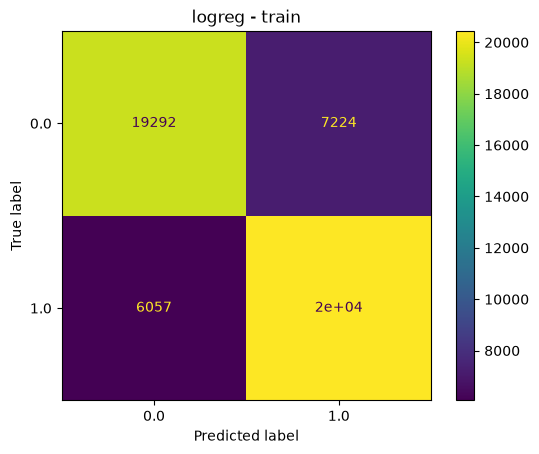

===== gradientboosting (TRAIN) =====
roc_auc 0.835
recall  0.802
f1      0.768
params  {'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__n_estimators': 200}



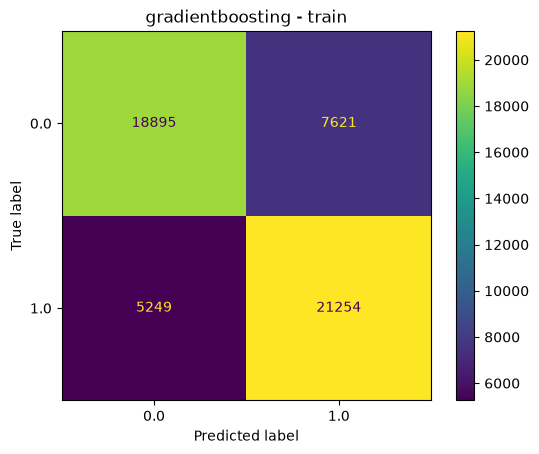

In [141]:
trained_models = {
    "logreg": grid_logreg,
    "gradientboosting": grid_gb,
}

for name, model in trained_models.items():
    y_pred = model.predict(X_train_final)
    y_proba = model.predict_proba(X_train_final)[:, 1]

    auc = roc_auc_score(y_train, y_proba)
    rec = recall_score(y_train, y_pred)
    f1 = f1_score(y_train, y_pred)

    print(f"===== {name} (TRAIN) =====")
    print(f"roc_auc {auc:.3f}")
    print(f"recall  {rec:.3f}")
    print(f"f1      {f1:.3f}")
    print(f"params  {model.best_params_}")
    print()

    ConfusionMatrixDisplay.from_estimator(model, X_train_final, y_train)
    plt.title(f"{name} - train")
    plt.show()



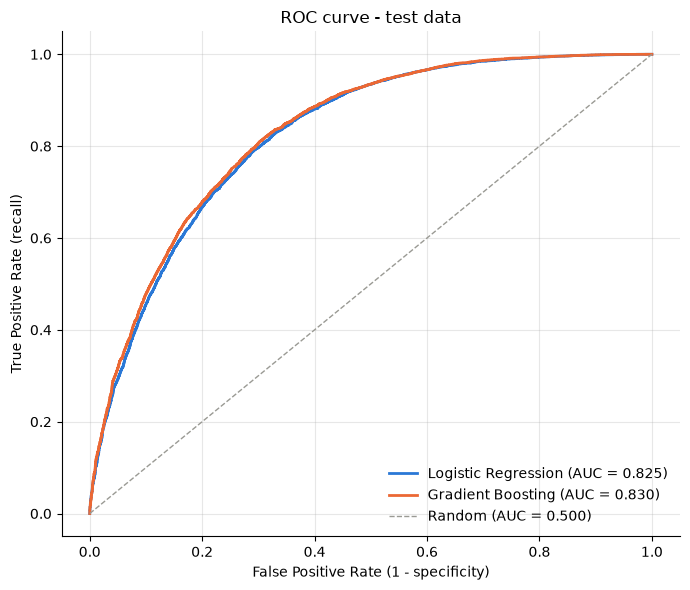

In [142]:
from sklearn.metrics import roc_curve

trained_models = {
    "Logistic Regression": grid_logreg,
    "Gradient Boosting": grid_gb,
}
colors = ["#2a78d6", "#eb6834"]

fig, ax = plt.subplots(figsize=(7, 6))

for (name, model), color in zip(trained_models.items(), colors):
    y_proba = model.predict_proba(X_test_final)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    ax.plot(fpr, tpr, color=color, linewidth=2,
            label=f"{name} (AUC = {auc:.3f})")

# random-guess baseline
ax.plot([0, 1], [0, 1], color="#9a9a94", linewidth=1,
        linestyle="--", label="Random (AUC = 0.500)")

ax.set_xlabel("False Positive Rate (1 - specificity)")
ax.set_ylabel("True Positive Rate (recall)")
ax.set_title("ROC curve - test data")
ax.legend(loc="lower right", frameon=False)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Test data

In [ ]:
# ===== logreg (TRAIN) =====
# roc_auc 0.825
# recall  0.771
# f1      0.755
# params  {'logisticregression__C': 0.01}

===== Logistic Regression (TEST) =====
   roc_auc  0.825
   recall   0.769
   f1       0.752



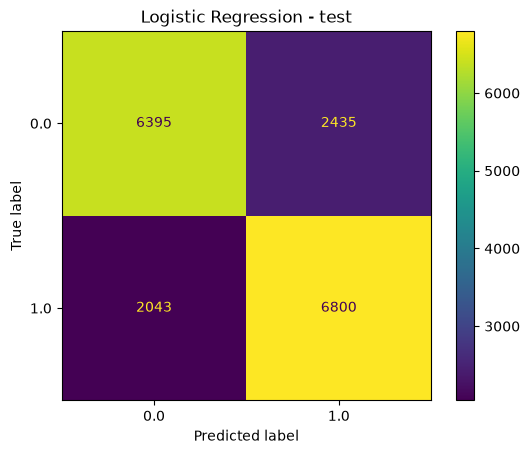

===== Gradient Boosting (TEST) =====
   roc_auc  0.830
   recall   0.798
   f1       0.763



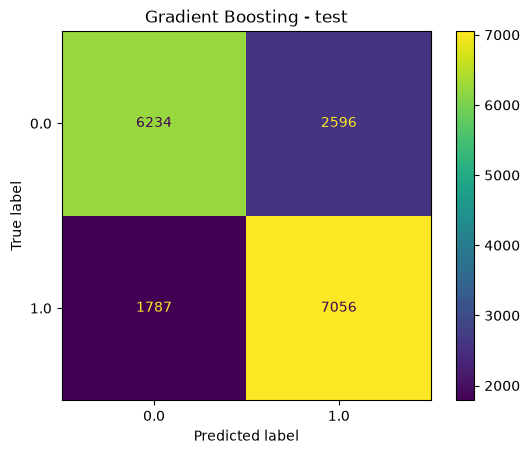

In [143]:
for name, model in trained_models.items():
    y_pred = model.predict(X_test_final)
    y_proba = model.predict_proba(X_test_final)[:, 1]

    print(f"===== {name} (TEST) =====")
    print(f"   roc_auc  {roc_auc_score(y_test, y_proba):.3f}")
    print(f"   recall   {recall_score(y_test, y_pred):.3f}")
    print(f"   f1       {f1_score(y_test, y_pred):.3f}\n")

    ConfusionMatrixDisplay.from_estimator(model, X_test_final, y_test)
    plt.title(f"{name} - test")
    plt.show()

===== gradientboosting (TRAIN) =====
roc_auc 0.835
recall  0.802
f1      0.768
params  {'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__n_estimators': 200}
